In [1]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
from scipy.stats import boxcox
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, skew, spearmanr, qmc
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



n = 31 (20 initial + 11 queried); newest x = [1.       0.994177 1.       1.      ], y = 8550.9919
best observed: row 29, x = [1. 1. 1. 1.], y = 8662.4825
newest ranks 2 of 31; skew raw 1.65, skew log -0.49




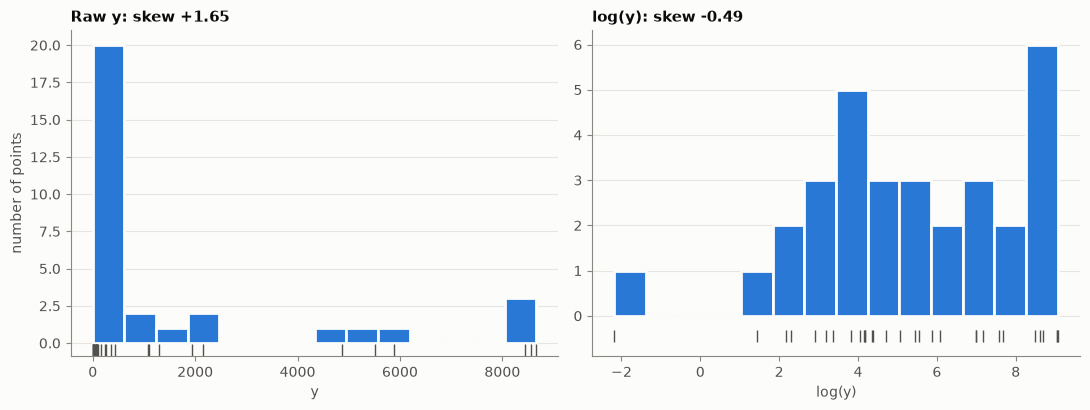

In [2]:
# -----------------------------------------------------------------------
# 1. Data
# -----------------------------------------------------------------------
X = np.load('..\Function_5_Data\Week_12_Data/F5_Week_12_inputs.npy')
y = np.load('..\Function_5_Data\Week_12_Data/F5_Week_12_outputs.npy')
n, d = X.shape
N_INITIAL = 20
NEW = n - 1
best = int(np.argmax(y))
CORNER = np.ones(d)
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[NEW], 6)}, y = {y[NEW]:.4f}")
print(f"best observed: row {best}, x = {np.round(X[best], 6)}, y = {y[best]:.4f}")
print(f"newest ranks {int((y > y[NEW]).sum()) + 1} of {n}; skew raw {skew(y):.2f}, skew log {skew(np.log(y)):.2f}")
print('\n')

# Fig 1: target distribution
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, v, xl) in zip(axes, [("Raw y", y, "y"), ("log(y)", np.log(y), "log(y)")]):
    ax.hist(v, bins=14, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(v, np.full(n, -0.45), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(f"{title}: skew {skew(v):+.2f}"); ax.set_xlabel(xl)
    ax.set_ylim(bottom=-0.9); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("number of points")
fig.tight_layout()


MODELS (LOO with hyperparameters fixed; errors in raw y)
  log-iso  ls=[0.532]  noise sd (own scale, normalised)=0.0001  own-scale LOO RMSE/std=0.590  Spearman=0.824  raw RMSE all=743  raw RMSE top 6=1608
  log-ARD  ls=[3.41  0.191 0.743 0.651]  noise sd (own scale, normalised)=0.0015  own-scale LOO RMSE/std=0.573  Spearman=0.855  raw RMSE all=740  raw RMSE top 6=1632
  raw-iso  ls=[1.999]  noise sd (own scale, normalised)=0.0115  own-scale LOO RMSE/std=0.104  Spearman=0.843  raw RMSE all=287  raw RMSE top 6=428
  raw-ARD  ls=[1.91  4.325 1.731 1.773]  noise sd (own scale, normalised)=0.0139  own-scale LOO RMSE/std=0.083  Spearman=0.845  raw RMSE all=228  raw RMSE top 6=133
  raw-ARD fitted noise sd = 38.4 (0.44% of the best value)




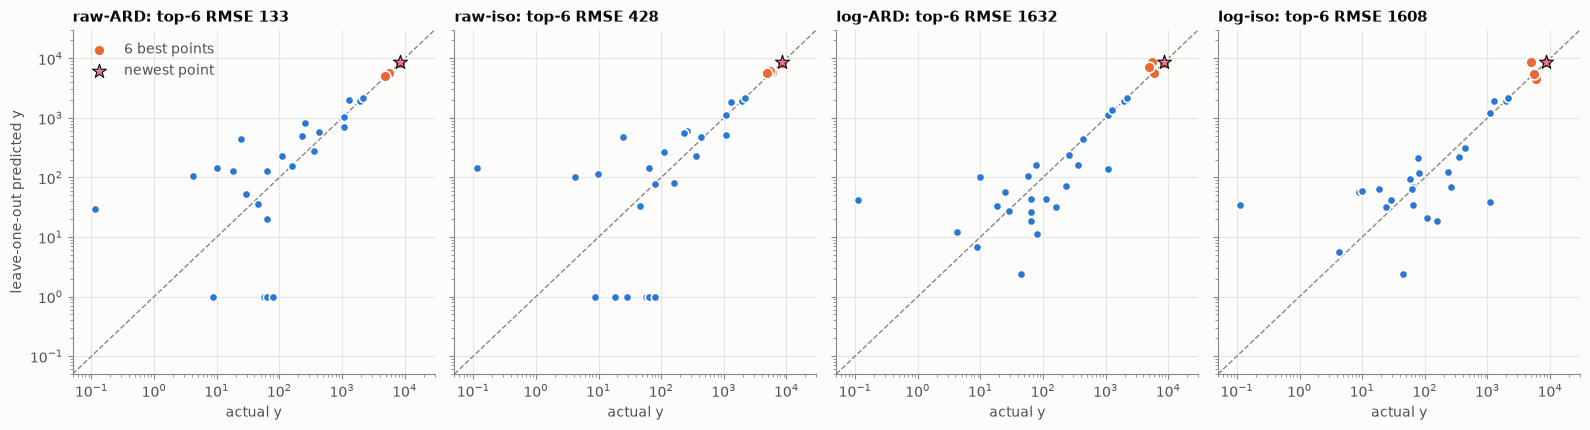

In [3]:
# ---------------------------------------------------------------- 
# Models
# ---------------------------------------------------------------- 
def fit(Xf, t, ard):
    k = (ConstantKernel(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                      length_scale_bounds=(1e-2, 1e2), nu=2.5)
         + WhiteKernel(1e-4, (1e-8, 1e-1)))
    return GaussianProcessRegressor(kernel=k, normalize_y=True, alpha=1e-10,
                                    n_restarts_optimizer=20, random_state=SEED).fit(Xf, t)

TARGETS = {"log": (np.log, np.exp), "raw": (lambda v: v.copy(), lambda m: m)}
models, loos = {}, {}
top = np.argsort(-y)[:6]
print("\nMODELS (LOO with hyperparameters fixed; errors in raw y)")
for tname, (f, back) in TARGETS.items():
    t = f(y)
    for ard in (False, True):
        key = f"{tname}-{'ARD' if ard else 'iso'}"
        gp = fit(X, t, ard)
        mu = np.empty(n)
        for i in range(n):
            keep = np.arange(n) != i
            g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, normalize_y=True,
                                         alpha=1e-10).fit(X[keep], t[keep])
            mu[i] = g.predict(X[i:i + 1])[0]
        yb = back(mu)
        models[key], loos[key] = gp, yb
        ls = np.atleast_1d(gp.kernel_.k1.k2.length_scale)
        print(f"  {key:8s} ls={np.round(ls, 3)}  noise sd (own scale, normalised)={np.sqrt(gp.kernel_.k2.noise_level):.4f}  "
              f"own-scale LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
              f"Spearman={spearmanr(y, yb)[0]:.3f}  raw RMSE all={np.sqrt(np.mean((y - yb) ** 2)):.0f}  "
              f"raw RMSE top 6={np.sqrt(np.mean((y[top] - yb[top]) ** 2)):.0f}")
raw_noise_sd = np.sqrt(models["raw-ARD"].kernel_.k2.noise_level) * y.std()
print(f"  raw-ARD fitted noise sd = {raw_noise_sd:.1f} ({100 * raw_noise_sd / y.max():.2f}% of the best value)")

def predict(key, Z):
    m, s = models[key].predict(np.atleast_2d(Z), return_std=True)
    return (np.exp(m), s) if key.startswith("log") else (m, s)

def p_improve(key, Z):
    m, s = models[key].predict(np.atleast_2d(Z), return_std=True)
    thr = np.log(y.max()) if key.startswith("log") else y.max()
    return norm.sf((thr - m) / np.maximum(s, 1e-12))

print('\n')
KEYS = ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]
# Fig 2: LOO predicted vs actual, raw y, log axes
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
for ax, key in zip(axes, KEYS):
    yb = np.maximum(loos[key], 1)
    lim = [5e-2, 3e4]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, yb, s=36, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], yb[top], s=60, color=ORANGE, edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.scatter(y[NEW], yb[NEW], s=110, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=5, label="newest point")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{key}: top-6 RMSE {np.sqrt(np.mean((y[top] - loos[key][top]) ** 2)):.0f}")
    ax.set_xlabel("actual y")
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()

In [4]:
# ---------------------------------------------------------------- 
# Week-11 prediction check
# ---------------------------------------------------------------- 

print(f"\nWEEK-11 PREDICTIONS at {np.round(X[NEW], 6)} (models refitted on the first {NEW} rows); observed {y[NEW]:.2f}")
prev = {}
for key in ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]:
    tname, kind = key.split("-")
    f, back = TARGETS[tname]
    g = fit(X[:NEW], f(y[:NEW]), kind == "ARD")
    m, s = g.predict(X[NEW:NEW + 1], return_std=True)
    pred = back(m)[0]
    # sd in raw units for the raw models; for log models, approximate by delta method
    sd_raw = s[0] if tname == "raw" else s[0] * pred
    prev[key] = (pred, sd_raw)
    print(f"  {key:8s} predicted {pred:8.0f} +/- {sd_raw:6.0f}   error {y[NEW] - pred:+7.0f}   z = {(y[NEW] - pred) / sd_raw:+.2f}")


WEEK-11 PREDICTIONS at [1.       0.994177 1.       1.      ] (models refitted on the first 30 rows); observed 8550.99
  raw-ARD  predicted     8613 +/-     40   error     -62   z = -1.53
  raw-iso  predicted     8590 +/-     41   error     -39   z = -0.96
  log-ARD  predicted     8740 +/-    870   error    -189   z = -0.22
  log-iso  predicted     8582 +/-    328   error     -31   z = -0.09



CANDIDATES: predicted y (P(observation > current best))
  A: corner again (1, 1, 1, 1)                     x = (1.000000, 1.000000, 1.000000, 1.000000)  dist from corner 0.0000  raw-ARD=8610 (0.120)  raw-iso=8618 (0.117)  log-ARD=8639 (0.287)  log-iso=8662 (0.499)
  B: x3 lowered by 0.006                           x = (1.000000, 1.000000, 0.994000, 1.000000)  dist from corner 0.0060  raw-ARD=8525 (0.001)  raw-iso=8534 (0.000)  log-ARD=8569 (0.232)  log-iso=8613 (0.406)
  C: x4 lowered by 0.006                           x = (1.000000, 1.000000, 1.000000, 0.994000)  dist from corner 0.0060  raw-ARD=8531 (0.002)  raw-iso=8540 (0.001)  log-ARD=8595 (0.338)  log-iso=8657 (0.490)
  D: raw-ARD highest P(improve), corner excluded   x = (1.000000, 0.000000, 1.000000, 1.000000)  dist from corner 1.0000  raw-ARD=5847 (0.002)  raw-iso=3254 (0.000)  log-ARD=189 (0.049)  log-iso=474 (0.098)
  E: log-ARD highest P(improve), corner excluded   x = (1.000000, 1.000000, 1.000000, 0.334957)  dist from co

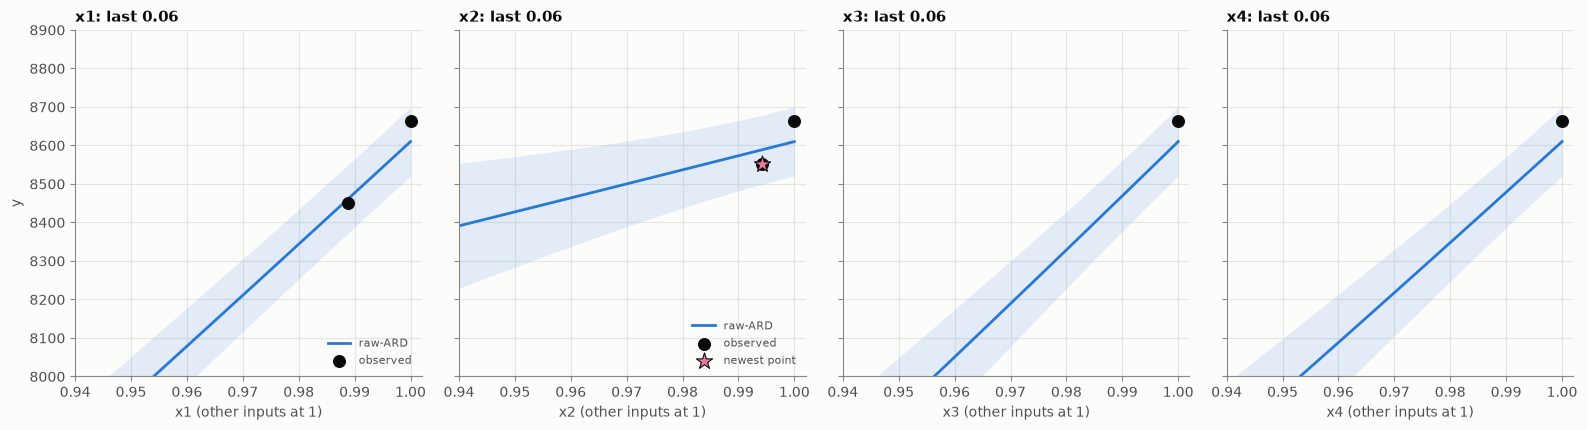

In [5]:
# ---------------------------------------------------------------- 
# Candidates
# ----------------------------------------------------------------

S = np.vstack([qmc.Sobol(d, seed=1).random(2 ** 15), np.array(np.meshgrid(*[[0, 1]] * d)).reshape(d, -1).T])
EPS = 0.006
exclude_corner = lambda Z: np.linalg.norm(Z - CORNER, axis=1) > 0.003
def argmax_excl(fn):
    v = fn(S) * exclude_corner(S)
    x0 = S[v.argmax()]
    r = minimize(lambda q: -fn(q[None])[0] * (1.0 if np.linalg.norm(q - CORNER) > 0.003 else 0.0), x0,
                 bounds=[(0, 1)] * d, method="L-BFGS-B")
    cand = r.x if (-r.fun >= v.max()) else x0
    return cand

cands = {
    "A: corner again (1, 1, 1, 1)": CORNER,
    "B: x3 lowered by 0.006": np.array([1.0, 1.0, 1 - EPS, 1.0]),
    "C: x4 lowered by 0.006": np.array([1.0, 1.0, 1.0, 1 - EPS]),
    "D: raw-ARD highest P(improve), corner excluded": argmax_excl(lambda Z: p_improve("raw-ARD", Z)),
    "E: log-ARD highest P(improve), corner excluded": argmax_excl(lambda Z: p_improve("log-ARD", Z)),
}
KEYS = ["raw-ARD", "raw-iso", "log-ARD", "log-iso"]
print("\nCANDIDATES: predicted y (P(observation > current best))")
for name, xc in cands.items():
    parts = [f"{k}={predict(k, xc)[0][0]:.0f} ({p_improve(k, xc)[0]:.3f})" for k in KEYS]
    print(f"  {name:48s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist from corner {np.linalg.norm(xc - CORNER):.4f}  " + "  ".join(parts))
print("  model predictions at the corner (observed 8662.48): " +
      "  ".join(f"{k}={predict(k, CORNER)[0][0]:.0f}" for k in KEYS))
print('\n')

# Fig 4: zoom on the last 0.05 of each input: observations and the raw-ARD fit
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), sharey=True)
xs = np.linspace(0.94, 1.0, 120)
for j, ax in enumerate(axes):
    Z = np.tile(CORNER, (len(xs), 1)); Z[:, j] = xs
    m, s = predict("raw-ARD", Z)
    ax.plot(xs, m, color=BLUE, lw=2, label="raw-ARD")
    ax.fill_between(xs, m - 2 * s, m + 2 * s, color=BLUE, alpha=0.12, lw=0)
    others = [k for k in range(d) if k != j]
    on = np.all(np.isclose(X[:, others], 1.0), axis=1) & (X[:, j] > 0.94)
    ax.scatter(X[on, j], y[on], s=70, color=INK, zorder=4, label="observed")
    if j == 1:
        ax.scatter(X[NEW, j], y[NEW], s=150, marker="*", color=MAGENTA, edgecolor=INK, linewidth=0.8, zorder=5, label="newest point")
    for k_ in (NEW,) if j == 1 else ():
        pass
    ax.set_xlabel(f"x{j + 1} (other inputs at 1)"); ax.set_title(f"x{j + 1}: last 0.06")
    ax.set_xlim(0.94, 1.002); ax.set_ylim(8000, 8900)
axes[0].set_ylabel("y")
axes[0].legend(frameon=False, loc="lower right", fontsize=8, labelcolor=INK2)
axes[1].legend(frameon=False, loc="lower right", fontsize=8, labelcolor=INK2)
fig.tight_layout()

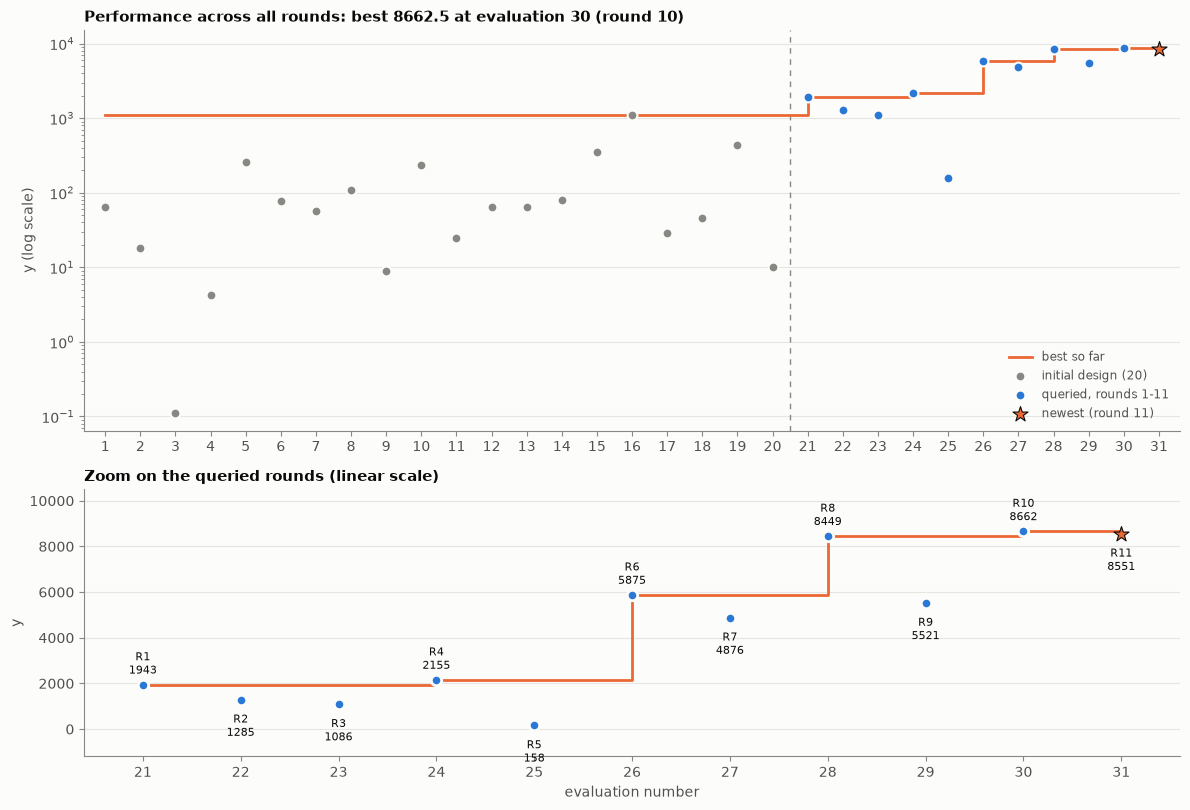

In [6]:
# Fig 1: performance across all rounds (log scale) with a linear zoom on the queried rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 8.2), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=ORANGE, lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=1.5,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:], y[N_INITIAL:], s=50, color=BLUE, edgecolor=SURFACE, linewidth=1.5,
           label=f"queried, rounds 1-{n - N_INITIAL}", zorder=3)
ax.scatter(idx[NEW], y[NEW], s=130, marker="*", color=ORANGE, edgecolor=INK, linewidth=0.8, zorder=4, label="newest (round 11)")
ax.set_yscale("log"); ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6)
ax.grid(axis="x", visible=False); ax.set_ylabel("y (log scale)")
ax.set_title(f"Performance across all rounds: best {y.max():.1f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=ORANGE, lw=2, zorder=2)
for i in q:
    star = i == NEW
    az.scatter(idx[i], y[i], s=130 if star else 56, marker="*" if star else "o", color=ORANGE if star else BLUE,
               edgecolor=INK if star else SURFACE, linewidth=0.8 if star else 2, zorder=3)
    az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.0f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-9 else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6); az.set_ylim(-1200, 10500)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds (linear scale)")
fig.tight_layout()